### Задание:
**Задача 1**
Изучите таблицу users_info, содержащую информацию о пользователях. Проведите разведочный анализ данных:

**Общая информация о таблице**
+ Сколько в таблице строк и столбцов?
+ Какие типы данных у каждого столбца?

**Пропущенные значения**
+Сколько пропущенных значений в каждом столбце?
+ Удалите все строки с пропущенными значениями. Какой процент данных был удалён?

**Выбросы по возрасту**
+ Рассчитайте границы для выбросов в колонке age с помощью метода IQR (межквартильного размаха).
+ Удалите выбросы из таблицы.

**Визуализация**
+ Постройте гистограмму (sns.histplot) распределения возрастов пользователей.



**Задача 2** 
Проанализируйте распределение пользователей по полу и городам:
+ Рассчитайте количество пользователей по каждому полу и городу с помощью группировки и агрегации.

+ Используйте pivot_table, чтобы представить данные:
— города в строках,
— пол в столбцах.
+ Для каждого города рассчитайте долю женщин среди всех пользователей.
+ Постройте столбчатую диаграмму (bar chart), чтобы сравнить долю женщин в разных городах.Какой город отличается от остальных?

**Задача 3** Сегментация

Загрузите таблицу payments_monthly.csv с платежами, очищенными от выбросов и сгруппированными по месяцам.

Рассчитайте среднее количество тренировок в месяц для каждого пользователя.

**Подсказка:** для создания групп используйте функцию cut из библиотеки pandas. Cut используется для деления числового столбца DataFrame на интервалы. 
+ Разделите пользователей на три группы по уровню активности:

— мало (редко тренируются),

— средне,

— много (тренируются часто).

+ Посчитайте, сколько пользователей входит в каждую из этих групп.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
users_info = pd.read_csv('users_info.csv')
users_info.head()

,id_user,city,age,gender
0,1000,СПб,44.0,female
1,1001,Москва,35.0,female
2,1002,Москва,34.0,male
3,1003,Москва,NaN,NaN
4,1004,Екатеринбург,60.0,male


### Задача 1. EDA

Размер таблицы: 1000 строк, 4 столбцов

Типы данных:
id_user      int64
city        object
age        float64
gender      object
dtype: object

Пропущенные значения по столбцам:
id_user     0
city        0
age        88
gender     89
dtype: int64

Удалено строк: 135 (13.50%)
Осталось строк: 865

Границы выбросов: [-6.50; 85.50]
Удалено выбросов: 0
Осталось наблюдений: 865


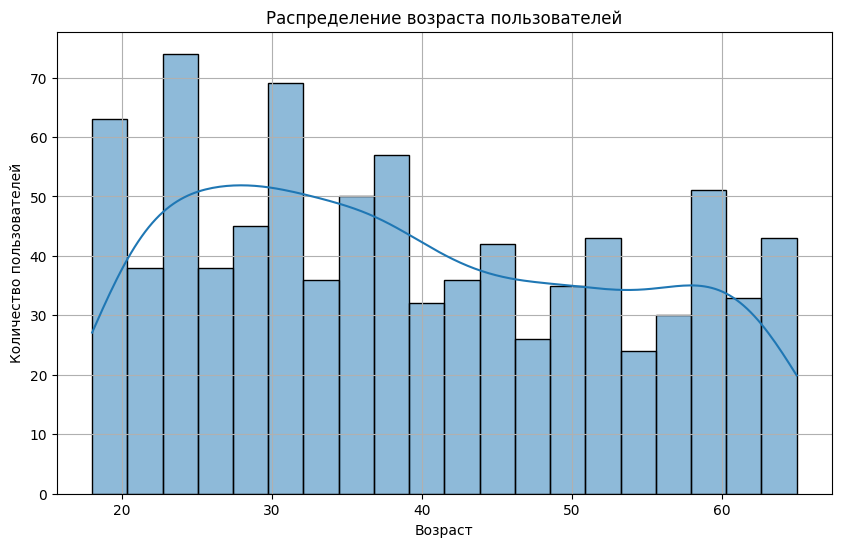

In [3]:
print(f"Размер таблицы: {users_info.shape[0]} строк, {users_info.shape[1]} столбцов")
print("\nТипы данных:")
print(users_info.dtypes)

print("\nПропущенные значения по столбцам:")
print(users_info.isnull().sum())

initial_rows = users_info.shape[0]
users_info_clean = users_info.dropna()
deleted_rows = initial_rows - users_info_clean.shape[0]
deleted_percent = (deleted_rows / initial_rows) * 100
print(f"\nУдалено строк: {deleted_rows} ({deleted_percent:.2f}%)")
print(f"Осталось строк: {users_info_clean.shape[0]}")

Q1 = users_info_clean['age'].quantile(0.25)
Q3 = users_info_clean['age'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
print(f"\nГраницы выбросов: [{lower_bound:.2f}; {upper_bound:.2f}]")

users_info_final = users_info_clean[
    (users_info_clean['age'] >= lower_bound) & 
    (users_info_clean['age'] <= upper_bound)
]
removed_outliers = users_info_clean.shape[0] - users_info_final.shape[0]
print(f"Удалено выбросов: {removed_outliers}")
print(f"Осталось наблюдений: {users_info_final.shape[0]}")

plt.figure(figsize=(10, 6))
sns.histplot(data=users_info_final, x='age', bins=20, kde=True)
plt.title('Распределение возраста пользователей')
plt.xlabel('Возраст')
plt.ylabel('Количество пользователей')
plt.grid()
plt.show()

### Задача 2. Доля пользователей-женщин по городам

Количество пользователей по городам и полу:
           city  gender  count
0  Екатеринбург  female     55
1  Екатеринбург    male     78
2        Казань  female     53
3        Казань    male     77
4        Москва  female    220

Pivot table:
gender        female   male
city                       
Екатеринбург    55.0   78.0
Казань          53.0   77.0
Москва         220.0  105.0
СПб            123.0  154.0

Доля женщин по городам:
gender        female_share
city                      
Москва            0.676923
СПб               0.444043
Екатеринбург      0.413534
Казань            0.407692


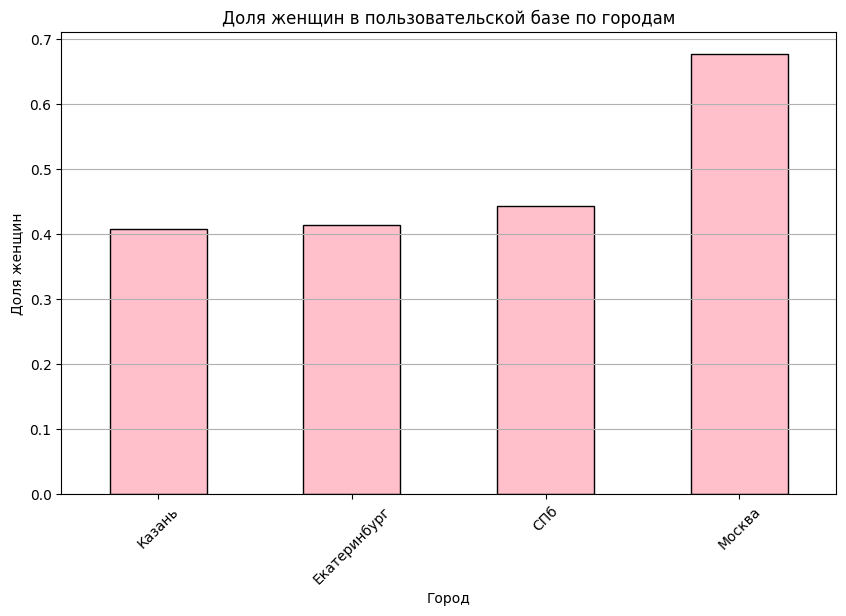


Город с наибольшей долей женщин: Москва


In [4]:
city_gender = users_info_final.groupby(['city', 'gender']).size().reset_index(name='count')
print("Количество пользователей по городам и полу:")
print(city_gender.head())

pivot = city_gender.pivot_table(index='city', columns='gender', values='count', fill_value=0)
print("\nPivot table:")
print(pivot)

pivot['total'] = pivot.sum(axis=1)
pivot['female_share'] = pivot['female'] / pivot['total']
print("\nДоля женщин по городам:")
print(pivot[['female_share']].sort_values('female_share', ascending=False))

plt.figure(figsize=(10, 6))
pivot['female_share'].sort_values().plot(kind='bar', color='pink', edgecolor='black')
plt.title('Доля женщин в пользовательской базе по городам')
plt.xlabel('Город')
plt.ylabel('Доля женщин')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

print(f"\nГород с наибольшей долей женщин: {pivot['female_share'].idxmax()}")

### Задача 3. Делим пользователей на бины

In [5]:
pay_mon = pd.read_csv('payments_monthly.csv')

In [6]:
avg_workouts = pay_mon.groupby('id_user')['cnt_total'].mean().reset_index(name='avg_cnt')
print("Среднее количество тренировок в месяц на пользователя:")
print(avg_workouts.head())
print(f"Среднее по всей выборке: {avg_workouts['avg_cnt'].mean():.2f}")

bins = [0, 4, 8, float('inf')]
labels = ['мало', 'средне', 'много']
avg_workouts['group'] = pd.cut(avg_workouts['avg_cnt'], bins=bins, labels=labels, right=True)

group_counts = avg_workouts['group'].value_counts().sort_index()
print("\nКоличество пользователей в каждой группе:")
print(group_counts)

Среднее количество тренировок в месяц на пользователя:
   id_user    avg_cnt
0     1000   3.666667
1     1001  11.727273
2     1002  11.636364
3     1003   5.166667
4     1004   2.000000
Среднее по всей выборке: 6.34

Количество пользователей в каждой группе:
group
мало      336
средне    375
много     258
Name: count, dtype: int64
